# Violin Plot

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

A mirrored density curve for each group, often with a mini box plot inside. It keeps a box plot's compact group comparison while showing the full shape of each distribution.

## When to use

- Compare distributions across groups when the shape matters (bimodality, skew)
- Show large samples per group

## Avoid when

- There are small samples (under ~30 per group)
- The audience is non-technical (box plots or histograms are more familiar)

## Alternatives

- Box plot
- Raincloud plot
- Ridgeline plot

## Example

Daily screen time (hours) by age group, with a split by weekday vs. weekend.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(31)
groups = {"13–17": 6.5, "18–29": 5.5, "30–49": 4.2, "50–64": 3.4, "65+": 3.0}
rows = []
for g, mu in groups.items():
    rows.append(pd.DataFrame({"age": g, "day": "Weekday", "hours": rng.gamma(mu * 2, 0.5, 300)}))
    rows.append(pd.DataFrame({"age": g, "day": "Weekend", "hours": rng.gamma(mu * 2.6, 0.5, 300)}))
df = pd.concat(rows, ignore_index=True)
x, y, hue = "age", "hours", "day"
labels = dict(x="Age group", y="Screen time (hours / day)", title="Daily screen time by age group")
df.groupby(["age", "day"])["hours"].median().unstack().round(1)

day,Weekday,Weekend
age,,
13–17,6.6,8.4
18–29,5.4,6.9
30–49,4.0,5.3
50–64,3.2,4.2
65+,2.9,3.6


### Plot

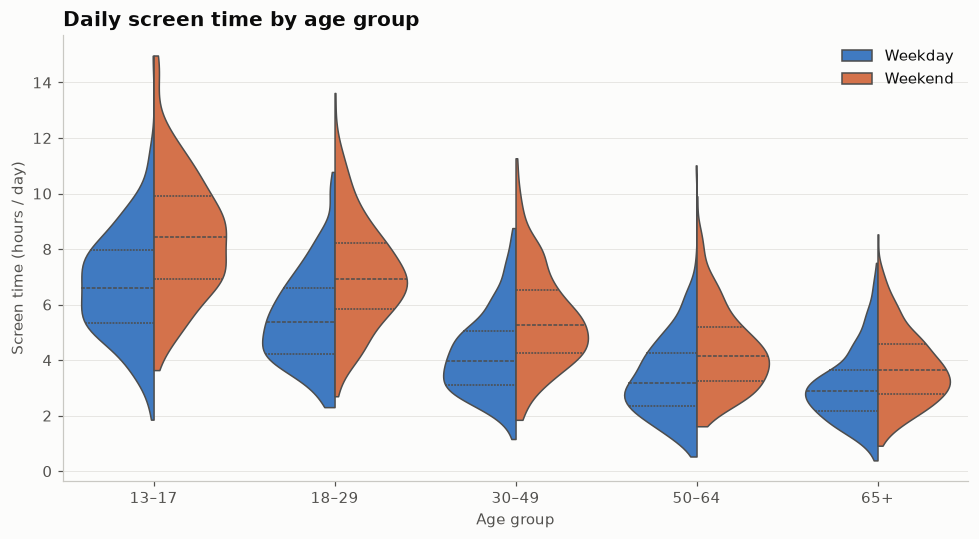

In [3]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=df, x=x, y=y, hue=hue, split=True, inner="quart",
               palette=PALETTE[:2], linewidth=1, cut=0, density_norm="width", ax=ax)
ax.set_xlabel(labels["x"])
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
ax.legend(title=None, loc="upper right")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Each violin shows where values concentrate: wider means more people. The left half is weekdays and the right half weekends, and the dashed lines are quartiles. Teenagers have the most screen time and the widest spread.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.graph_objects as go
fig = go.Figure()
for color, side, (name, g) in zip(PALETTE, ["negative", "positive"], df.groupby(hue, observed=True)):
    fig.add_trace(go.Violin(x=g[x], y=g[y], name=str(name), side=side, line_color=color,
                            fillcolor=color, opacity=0.75, meanline_visible=True, points=False))
fig.update_layout(violinmode="overlay", violingap=0.1, title=labels["title"],
                  xaxis_title=labels["x"], yaxis_title=labels["y"])
fig.show()

## Try it with real data

**Source:** plotly.express.data.tips() — restaurant tipping data (Bryant & Smith 1995), bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
import plotly.express as px
df = px.data.tips()
df["day"] = pd.Categorical(df["day"], ["Thur", "Fri", "Sat", "Sun"])   # calendar order
x, y, hue = "day", "total_bill", "sex"
labels = dict(x="Day", y="Total bill ($)", title="Restaurant bills by day and sex")
df.groupby([x, hue], observed=True)[y].median().unstack().round(1)

sex,Female,Male
day,,
Thur,13.8,17.0
Fri,15.4,17.2
Sat,18.4,18.2
Sun,17.4,20.7


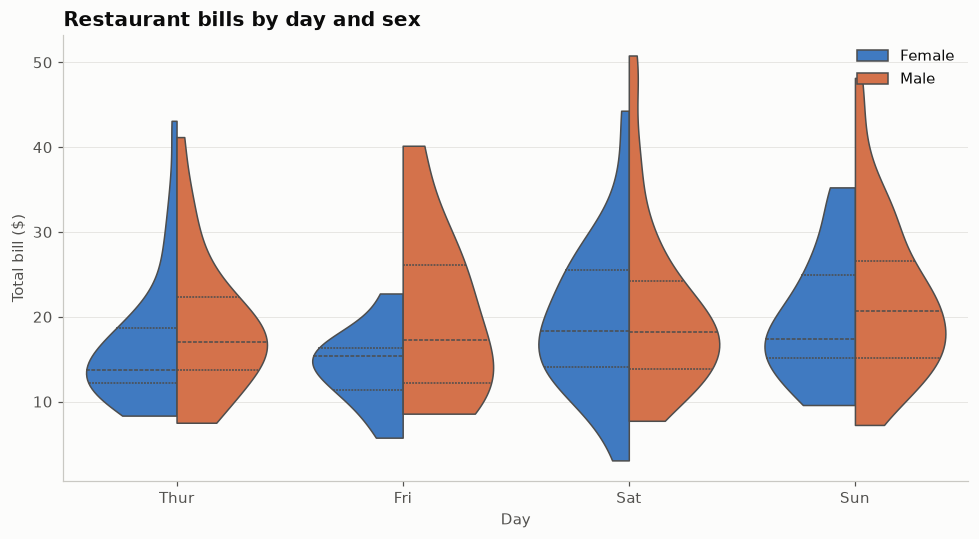

In [6]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=df, x=x, y=y, hue=hue, split=True, inner="quart",
               palette=PALETTE[:2], linewidth=1, cut=0, density_norm="width", ax=ax)
ax.set_xlabel(labels["x"])
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
ax.legend(title=None, loc="upper right")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

---
Standalone script: [`violin_plot.py`](violin_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)